# Chapitre 9 - Cours 5 : le consensus en pratique, Raft

Le cours précédent a montré que le consensus équivaut à un **journal partagé**, et
qu'un journal tenu par un leader unique est facile... tant que le leader ne tombe pas.
Les algorithmes de consensus utilisés en pratique (Raft, Multi-Paxos, Zab,
Viewstamped Replication) sont essentiellement de la **réplication à leader unique avec
élection et bascule automatiques, sans cerveau divisé ni perte d'écriture validée**. Ce
notebook implémente **Raft** sur le simulateur (`cs.RaftNode`), l'observe sur des
diagrammes espace-temps, le soumet à des pannes et à des partitions, vérifie sa sûreté
et mesure ce qu'il coûte. Il couvre la fin de la section *Fault-Tolerant Consensus* : *Consensus algorithms and total order broadcast*, *Single-leader replication and consensus*, *Epoch numbering and quorums*, *Limitations of consensus*.

**Plan.**

1. De la réplication à leader unique au consensus.
2. Mandats et quorums qui se recoupent.
3. Raft sur le simulateur : l'élection.
4. Réplication du journal et validation par majorité.
5. Pannes et partitions : le leader isolé, les lectures linéarisables.
6. Le nouveau leader doit être à jour.
7. Avantages et limites du consensus.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
TERM_COLORS = [GRAY, INDIGO, TEAL, AMBER, VIOLET, SKY, ROSE, GREEN, SLATE]


def dessine_journaux(nodes, ax, titre, sous_titre=""):
    """Grille des journaux : une ligne par nœud, une case par entrée colorée par mandat ;
    trait vert = indice de validation connu du nœud, contour épais = leader."""
    names = list(nodes)
    width = max(len(n.log) for n in nodes.values())
    for i, x in enumerate(names):
        nd = nodes[x]
        y = len(names) - 1 - i
        for k, e in enumerate(nd.log[1:], start=1):
            c = TERM_COLORS[e.term % len(TERM_COLORS)]
            cmd = e.cmd
            lab = "·" if cmd[0] == "noop" else (f"x={cmd[2]}" if cmd[0] == "set" else
                                                 ("lect." if cmd[0] == "read" else f"cas→{cmd[3]}"))
            ax.add_patch(plt.Rectangle((k - 0.45, y - 0.35), 0.9, 0.7, facecolor=LIGHT.get(c, "#F1F5F9"),
                                       edgecolor=c, lw=1.4))
            ax.text(k, y + 0.08, lab, ha="center", va="center", fontsize=8, color=SLATE)
            ax.text(k, y - 0.22, f"m{e.term}", ha="center", va="center", fontsize=6.5, color=c)
        if nd.commit:
            ax.plot([nd.commit + 0.5] * 2, [y - 0.45, y + 0.45], color=GREEN, lw=2.5)
        state = "leader" if nd.role == "leader" else ("en panne" if not nd.up else nd.role.replace("follower", "suiveur").replace("candidate", "candidat"))
        ax.text(-0.2, y, f"{x} ({state}, m{nd.term})", ha="right", va="center", fontsize=8.5,
                color=ROSE if not nd.up else SLATE, fontweight="bold" if nd.role == "leader" else "normal")
    ax.set_xlim(-0.1, width + 0.2); ax.set_ylim(-0.6, len(names) - 0.4)
    ax.set_xticks(range(1, width)); ax.set_yticks([]); ax.grid(False)
    for s_ in ("left", "top", "right"):
        ax.spines[s_].set_visible(False)
    ax.set_xlabel("indice dans le journal")
    ax.set_title(titre)
    if sous_titre:
        subtitle(ax, sous_titre)


def zoom(st, t0, t1):
    """Restreint un diagramme espace-temps à [t0, t1] en gardant les noms des nœuds visibles."""
    st.ax.set_xlim(t0 - 0.02 * (t1 - t0), t1)
    for txt in st.ax.texts[:len(st.nodes)]:
        txt.set_x(t0 - 0.015 * (t1 - t0))


def leader_actuel(nodes):
    ls = [x for x, n in nodes.items() if n.role == "leader" and n.up]
    return max(ls, key=lambda x: nodes[x].term) if ls else None

## 1. De la réplication à leader unique au consensus (section *Single-leader replication and consensus*)

Un journal partagé est facile si **un seul** leader a le droit d'y ajouter des entrées. La
question est : que faire quand il tombe ? Les bases à leader unique traditionnelles ne
répondaient pas : la **bascule** était confiée à un administrateur. Outre l'indisponibilité
(un humain ne réagit pas en millisecondes), cela viole la **terminaison** du consensus.
Il faut donc que l'algorithme **élise lui-même** un nouveau leader.

Difficulté : pour éviter le **cerveau divisé** (deux nœuds qui se croient leaders et
prennent des décisions contradictoires), tous les nœuds doivent s'accorder sur l'identité
du leader. Il faudrait donc un consensus pour élire un leader... et un leader pour obtenir
un consensus. Comment sortir de ce cercle ?

> **À retenir.** Le consensus en pratique, c'est la réplication à leader unique **plus**
> une élection automatique sûre. Le défi est d'élire sans déjà disposer d'un consensus.

## 2. Mandats et quorums qui se recoupent (section *Epoch numbering and quorums*)

Les algorithmes de consensus ne garantissent **pas** qu'il n'y ait qu'un leader à chaque
instant. Ils garantissent plus faible : ils numérotent des **époques** (numéro de scrutin
chez Paxos, numéro de vue chez Viewstamped Replication, **mandat** ou *term* chez Raft) et
assurent qu'**au sein d'une époque, le leader est unique**.

- Un nœud qui n'entend plus le leader pendant un certain délai lance une élection avec un
  numéro d'époque **plus grand** que tous ceux qu'il connaît.
- En cas de conflit entre deux leaders d'époques différentes (l'ancien n'était pas mort,
  juste lent), celui de l'époque **la plus grande** l'emporte.
- Avant d'ajouter une entrée, le leader recueille les votes d'un **quorum** (en général
  une majorité) ; un nœud ne vote oui que s'il ne connaît pas de leader d'époque plus
  grande.

Il y a donc **deux votes** : un pour élire le leader, un pour chaque proposition. Les
quorums des deux votes **se recoupent** : au moins un nœud qui accepte une proposition a
participé à la dernière élection réussie. Si aucun nœud du quorum ne signale une époque
plus grande, le leader sait qu'aucune élection plus récente n'a abouti, et il peut
ajouter l'entrée sans danger.

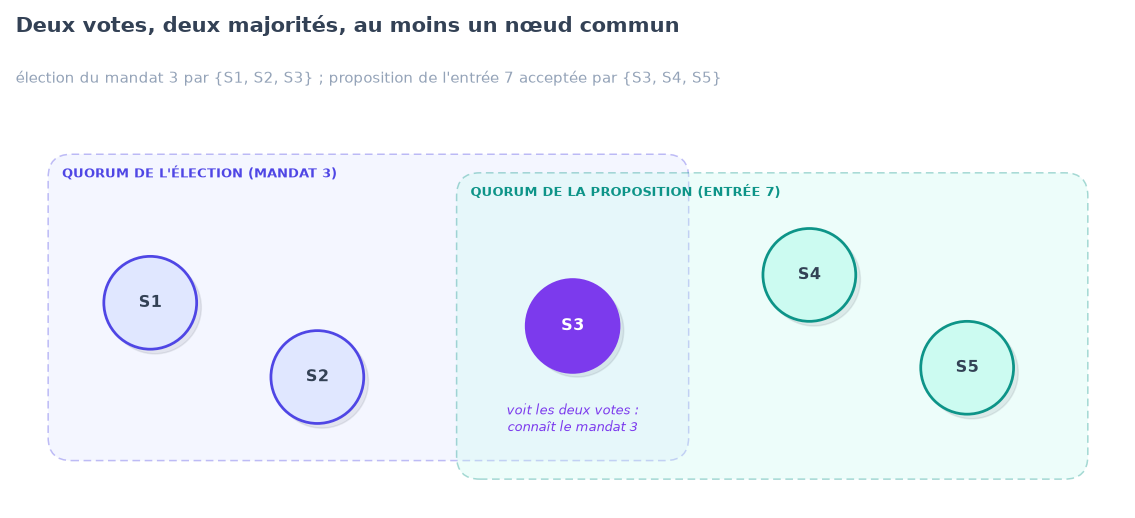

In [2]:
d = Diagram(12, 4.4, title="Deux votes, deux majorités, au moins un nœud commun",
            subtitle="élection du mandat 3 par {S1, S2, S3} ; proposition de l'entrée 7 acceptée par {S3, S4, S5}")
d.group(0.4, 0.5, 7.3, 3.8, "quorum de l'élection (mandat 3)", color=INDIGO)
d.group(4.8, 0.3, 11.6, 3.6, "quorum de la proposition (entrée 7)", color=TEAL)
for name, x, y, c in [("S1", 1.5, 2.2, INDIGO), ("S2", 3.3, 1.4, INDIGO), ("S3", 6.05, 1.95, VIOLET),
                      ("S4", 8.6, 2.5, TEAL), ("S5", 10.3, 1.5, TEAL)]:
    d.box(name, x, y, name, kind="circle", w=1.0, color=c, filled=name == "S3")
d.note(6.05, 0.95, "voit les deux votes :\nconnaît le mandat 3", color=VIOLET, fontsize=8.5)
d.show()

Ces deux tours de vote ressemblent superficiellement à la validation à deux phases
(cours 3), mais ce sont des protocoles très différents : dans un consensus,
**n'importe quel** nœud peut lancer une élection et il suffit d'un **quorum** de réponses ;
dans 2PC, seul le coordinateur sollicite des votes et il lui faut le **oui de tous** les
participants.

> **À retenir.** Un leader unique **par époque**, des époques croissantes, et des quorums
> d'élection et de proposition qui se recoupent : c'est la structure commune de Raft,
> Multi-Paxos, Zab et Viewstamped Replication.